In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import os
from scipy.cluster import hierarchy
import matplotlib.colors as mcolors

In [ ]:
# directory and data file settings
psites_f = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/TMT_control_centered_log2fc.csv"
desites_f = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/significant_phospho_pairwise_ids_and_flanks.csv"

out_dir = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig1/des_heatmap"

os.makedirs(out_dir, exist_ok=True)
os.makedirs(f"{out_dir}/figures", exist_ok=True)
os.makedirs(f"{out_dir}/out_files", exist_ok=True)
os.chdir(out_dir)

In [24]:
# load DE sites:
desites = pd.read_csv(desites_f)['id'].tolist()
print(f"Number of unique phosphopeptides: {len(desites)}")

Number of unique phosphopeptides: 1220


In [23]:
# load prot. data and subset to desites
prot_df = pd.read_csv(psites_f)
psite_id_map = prot_df[["id", "geneSymbol"]].copy()
prot_df.set_index("id", inplace=True)
prot_df.drop(columns=["geneSymbol"], inplace=True)
prot_df = prot_df.loc[
    desites,
].copy()
print(prot_df.iloc[0:4,0:4])
print(f"Number of unique proteins: {len(set([id.split('_')[0] for id in prot_df.index.tolist()]))}")


                             PBS_0_R1  PBS_0_R2  IL6_20_R1  IL6_20_R2
id                                                                   
E9Q616_S136s_1_1_136_136    -0.035273  0.035273   1.085330   1.265706
E9Q616_T736t_1_1_736_736    -0.065165  0.065165   0.409792   0.493452
E9Q616_S2985s_1_1_2985_2985 -0.438532  0.438532   2.226018   2.443258
E9Q616_S4184s_1_1_4184_4184  0.013959 -0.013959  -0.378337  -0.314605
Number of unique proteins: 851


In [5]:
avg_cols = ['PBS_0', 'IL6_20', 'IL6_45', 'IL6_90', 'IL10_20', 'IL10_45', 'IL10_90']

prot_df_avg = pd.DataFrame(index=prot_df.index)
for col in avg_cols:
    prot_df_avg[col] = (prot_df[f'{col}_R1'] + prot_df[f'{col}_R2']) / 2

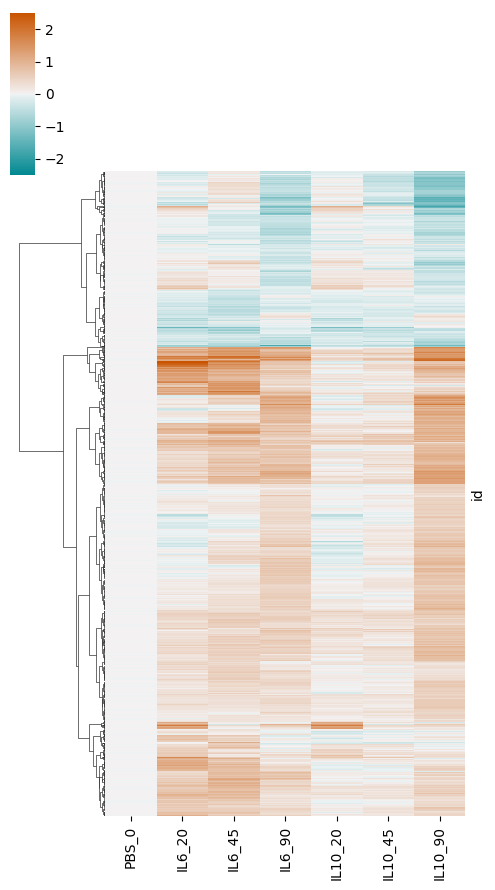

In [6]:
# heatmap 
c = sns.color_palette("RdBu_r", as_cmap=True)
cmap = sns.diverging_palette(200, 30,s=130, as_cmap=True)
# c2 = sns.color_palette(sns.diverging_palette(200, 30,s=130, n=7))
prot_heatmap_avg = sns.clustermap(prot_df_avg, metric='euclidean',method='ward', cmap=cmap, z_score=None,
                              col_cluster=False,yticklabels=False, figsize=(5,9), vmin=-2.5, vmax=2.5)
# prot_heatmap_avg = sns.clustermap(prot_df_avg, metric='correlation',method='average', cmap=cmap, z_score=None,
#                               col_cluster=False,yticklabels=False, figsize=(5,9), vmin=-2.5, vmax=2.5)
plt.savefig(f'{out_dir}/figures/pairwise_DEsites_avg.png',format='png')
plt.savefig(f'{out_dir}/figures/pairwise_DEsites_avg.svg',format='png')
plt.show()


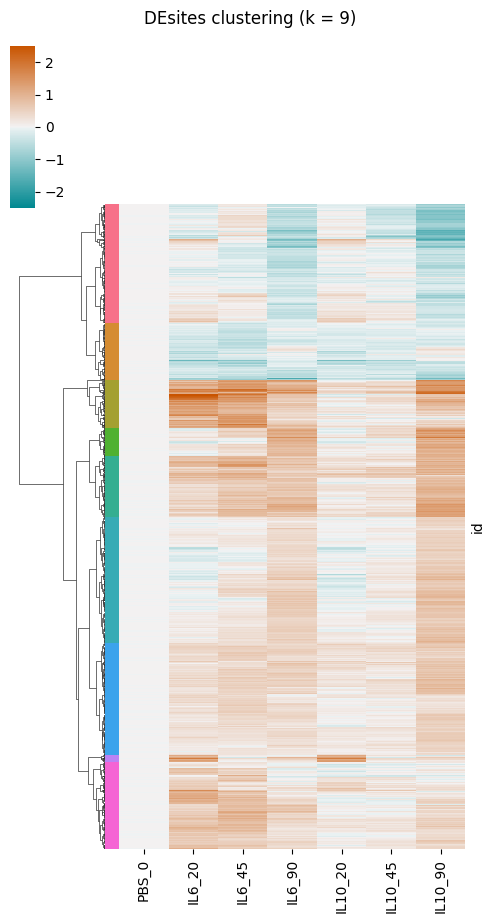

In [7]:
# ---- Parameters ----
k = 15
fig_out_dir = f"{out_dir}/figures"
os.makedirs(fig_out_dir, exist_ok=True)

# ---- Get linkage + row order from existing clustered heatmap ----
link = prot_heatmap_avg.dendrogram_row.linkage
ord_ind = prot_heatmap_avg.dendrogram_row.reordered_ind

# ---- Cut tree into k clusters ----
clus_assign = hierarchy.fcluster(link, t=k, criterion='maxclust')

# ---- Manually merge small clusters ----
# Key = cluster to absorb, Value = cluster to merge it into
# Run once first without this to see cluster numbers, then fill in
merge_map = {
    2: 1,
    3: 1,
    6: 5,
    7: 5,
    8: 5,
    15: 14
}
clus_assign = np.array([merge_map.get(c, c) for c in clus_assign])

# Remap to contiguous 1..n labels
unique = sorted(set(clus_assign))
remap = {old: new for new, old in enumerate(unique, 1)}
clus_assign = np.array([remap[c] for c in clus_assign])

k_final = len(unique)

# ---- Color palette ----
network_pal = sns.color_palette("husl", k_final)

# ---- Assign colors aligned to reordered rows ----
clus_colors = np.zeros((len(ord_ind), 3))

for i in range(len(ord_ind)):
    clus_colors[i, :] = network_pal[clus_assign[i] - 1]

# ---- Plot final heatmap (NO reclustering) ----
g = sns.clustermap(
    prot_df_avg,
    row_linkage=link,          # use existing clustering
    col_cluster=False,
    row_colors=clus_colors,
    cmap=cmap,
    z_score=None,
    vmin=-2.5,
    vmax=2.5,
    figsize=(5, 9),
    yticklabels=False
)

g.fig.suptitle(f"DEsites clustering (k = {k_final})", y=1.02)  # was k

out_f = f"{fig_out_dir}/pairwise_DEsites_heatmap_{k_final}_clusters.png"  # was k
plt.savefig(out_f, dpi=300, bbox_inches="tight")
out_f = f"{fig_out_dir}/pairwise_DEsites_heatmap_{k_final}_clusters.svg"  # was k
plt.savefig(out_f, dpi=300, bbox_inches="tight")

In [8]:
clus_ordered = clus_assign[ord_ind]
row_labels_ordered = prot_df_avg.index[ord_ind]

# Show only where cluster changes (top → bottom of heatmap)
prev = None
for i, (label, c) in enumerate(zip(row_labels_ordered, clus_ordered)):
    if c != prev:
        print(f"row {i:>4d} | cluster {c} | {label}")
        prev = c

row    0 | cluster 1 | P83741-3_S2282s_1_0_2280_2282
row  224 | cluster 2 | Q60929-3_S235s_1_1_235_235
row  332 | cluster 3 | P42227_Y705y_1_1_705_705
row  423 | cluster 4 | Q5SFM8_S566s_1_1_566_566
row  475 | cluster 5 | E9Q6J5-3_S1073s_1_0_1071_1073
row  591 | cluster 6 | F8WIJ0_T985t_1_1_985_985
row  830 | cluster 7 | P98078_S328sT329t_2_1_325_329
row 1041 | cluster 8 | E9QAS5_S1308s_1_1_1308_1308
row 1055 | cluster 9 | Q8BG40_S362sS363s_2_1_360_363


In [9]:
# ---- Get heatmap row order ----
ord_ind = prot_heatmap_avg.dendrogram_row.reordered_ind

# ---- Build cluster dataframe aligned to original order ----
final_clus_df = pd.DataFrame({
    "id": prot_df_avg.index,
    "cluster": clus_assign
})

# ---- Add gene symbols via merge ----
final_clus_df = final_clus_df.merge(
    psite_id_map,
    how="left",
    on="id"
)

# ---- Add cluster colors ----
network_pal = sns.color_palette("husl", k_final)  # was k

final_clus_df["cluster_color"] = final_clus_df["cluster"].apply(
    lambda x: mcolors.rgb2hex(network_pal[x-1])
)

# ---- Reorder to match heatmap row order ----
final_clus_df = final_clus_df.iloc[ord_ind].reset_index(drop=True)

# ---- Save ----
final_clus_df.to_csv(
    f"{out_dir}/out_files/pairwise_DEsites_{k_final}_clusters_ordered.csv",  # was k
    index=False
)

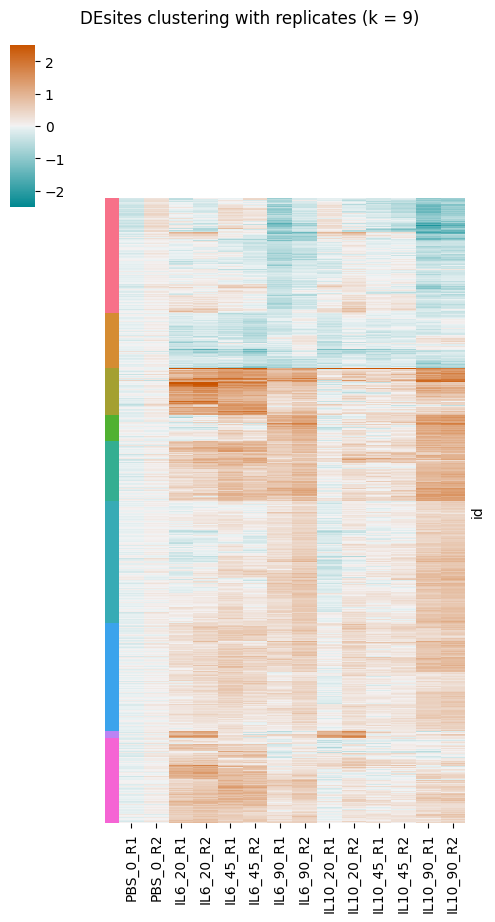

In [10]:
# ---- Reorder dataframe using saved order ----
ordered_ids = final_clus_df["id"].values
prot_df_ordered = prot_df.loc[ordered_ids]

# ---- Extract row colors from saved dataframe ----
row_colors = final_clus_df["cluster_color"].values

# ---- Plot heatmap WITHOUT clustering ----
g2 = sns.clustermap(
    prot_df_ordered,
    row_cluster=False,
    col_cluster=False,
    row_colors=row_colors,
    cmap=cmap,
    z_score=None,
    vmin=-2.5,
    vmax=2.5,
    yticklabels=False,
    figsize=(5, 9)
)

g2.fig.suptitle(f"DEsites clustering with replicates (k = {k_final})", y=1.02)
g2.ax_heatmap.collections[0].set_rasterized(True)

plt.savefig(f"{fig_out_dir}/pairwise_DEsites_heatmap_{k_final}_clusters_replicates.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{fig_out_dir}/pairwise_DEsites_heatmap_{k_final}_clusters_replicates.svg", dpi=300, bbox_inches="tight")
plt.show()